<center><h1>Zhao_Yibo_HW5</h1></center>
<br>
<br>

Name: Zhao Yibo
<br>
Github Username: Artmu-bo
<br>
USC ID: 5635641435

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score

from xgboost import XGBRegressor   
# pip install xgboost  (if GridSearchCV complains about __sklearn_tags__, run: pip install -U xgboost)

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', 200)
RANDOM_STATE = 552

DATA_DIR = Path('../data')

### (a) Obtain Data

Get the Acute Inflammations Data Set

In [2]:
cols = ['Temperature', 'Nausea', 'LumbarPain', 'UrinePushing',
        'MicturitionPains', 'BurningUrethra',      # 6 features
        'Inflammation', 'Nephritis']               # 2 labels
ai = pd.read_csv(DATA_DIR / 'diagnosis.data', sep='\t', header=None, names=cols,
                 encoding='utf-16', decimal=',')
ai[cols[1:]] = (ai[cols[1:]].apply(lambda s: s.str.strip()) == 'yes').astype(int)

features = cols[:6]
labels = cols[6:]      # Inflammation = inflammation of urinary bladder, Nephritis = nephritis of renal pelvis origin
X1, Y1 = ai[features], ai[labels]

print('Shape:', ai.shape)
display(ai.head())
print('Number of patients for each label combination:')
print(ai.groupby(labels).size())

Shape: (120, 8)


,Temperature,Nausea,LumbarPain,UrinePushing,MicturitionPains,BurningUrethra,Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


Number of patients for each label combination:
Inflammation  Nephritis
0             0            30
              1            31
1             0            40
              1            19
dtype: int64


### (b) Build a decision tree

This is a multi-label problem (two binary labels per patient). So there are three ways to build a tree:

1. **Label powerset (LP):** treat each combination of the two labels as one class, giving a 4-class problem (none / inflammation only / nephritis only / both), and fit one tree.
2. **Native multi-output tree:** scikit-learn's `DecisionTreeClassifier` accepts a 2-column `y` and picks each split to reduce the impurity of both labels together.
3. **Binary relevance (BR):** fit one independent tree per label.

The main tree below uses the label powerset approach. The other two are also fitted afterwards for comparison.

diagnosis
inflammation only    40
nephritis only       31
none                 30
both                 19
Name: count, dtype: int64 

Label powerset tree: training accuracy = 1.000, depth = 4, leaves = 6


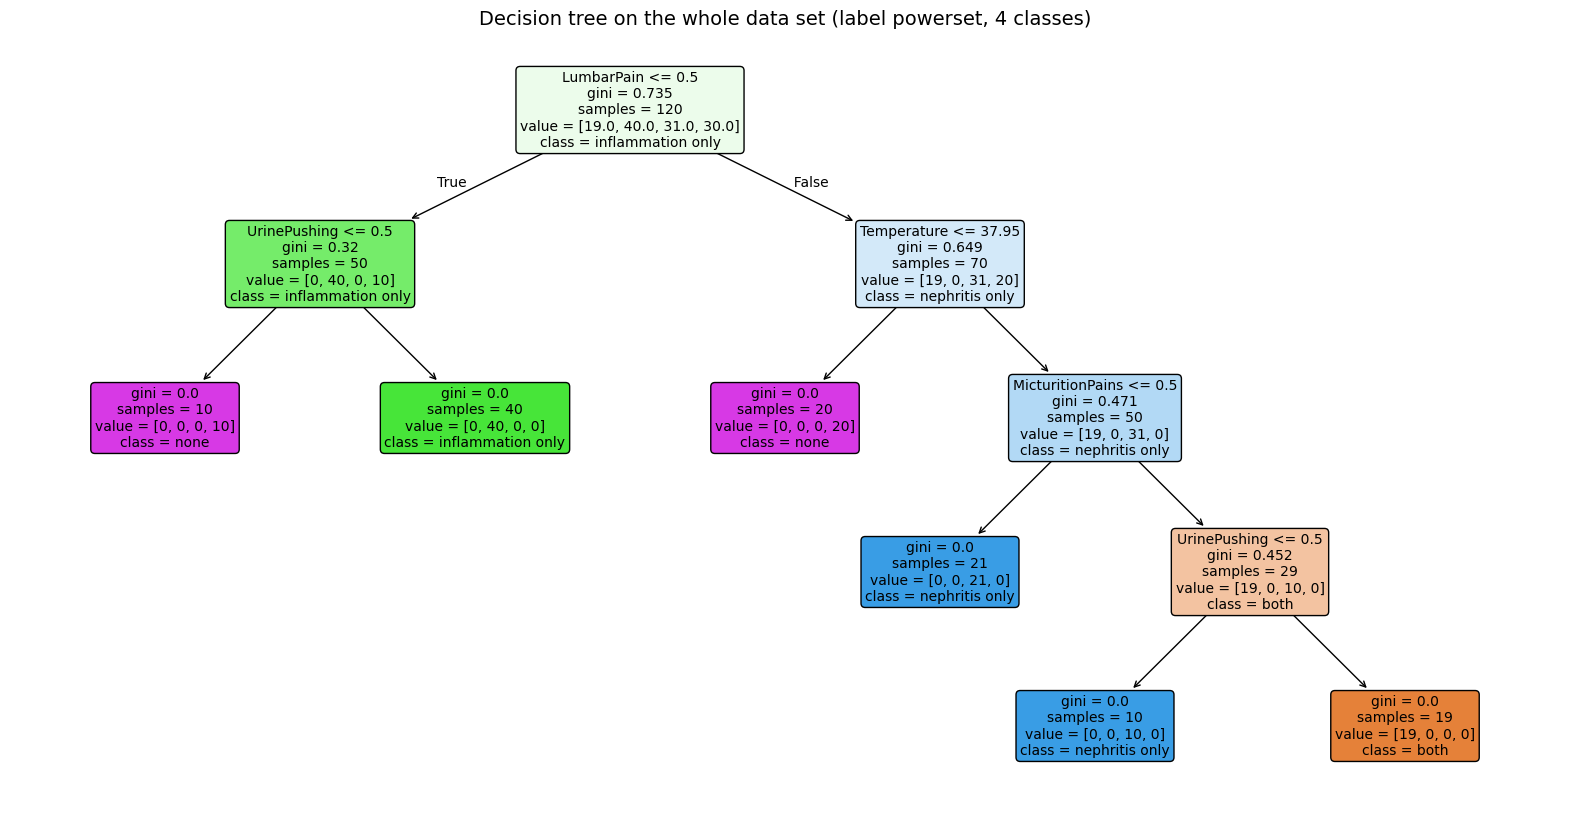

In [3]:
# Label powerset: 

lp_map = {(0, 0): 'none', (1, 0): 'inflammation only', (0, 1): 'nephritis only', (1, 1): 'both'} #new labels
y_lp = pd.Series([lp_map[tuple(r)] for r in Y1.values], name='diagnosis') 
print(y_lp.value_counts(), '\n') #check number for each new label

tree_lp = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X1, y_lp)
print(f'Label powerset tree: training accuracy = {tree_lp.score(X1, y_lp):.3f}, '
      f'depth = {tree_lp.get_depth()}, leaves = {tree_lp.get_n_leaves()}')

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(tree_lp, feature_names=features, class_names=list(tree_lp.classes_),
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title('Decision tree on the whole data set (label powerset, 4 classes)', fontsize=14)
plt.show()

For comparison, the native multi-output tree and the two binary-relevance trees:

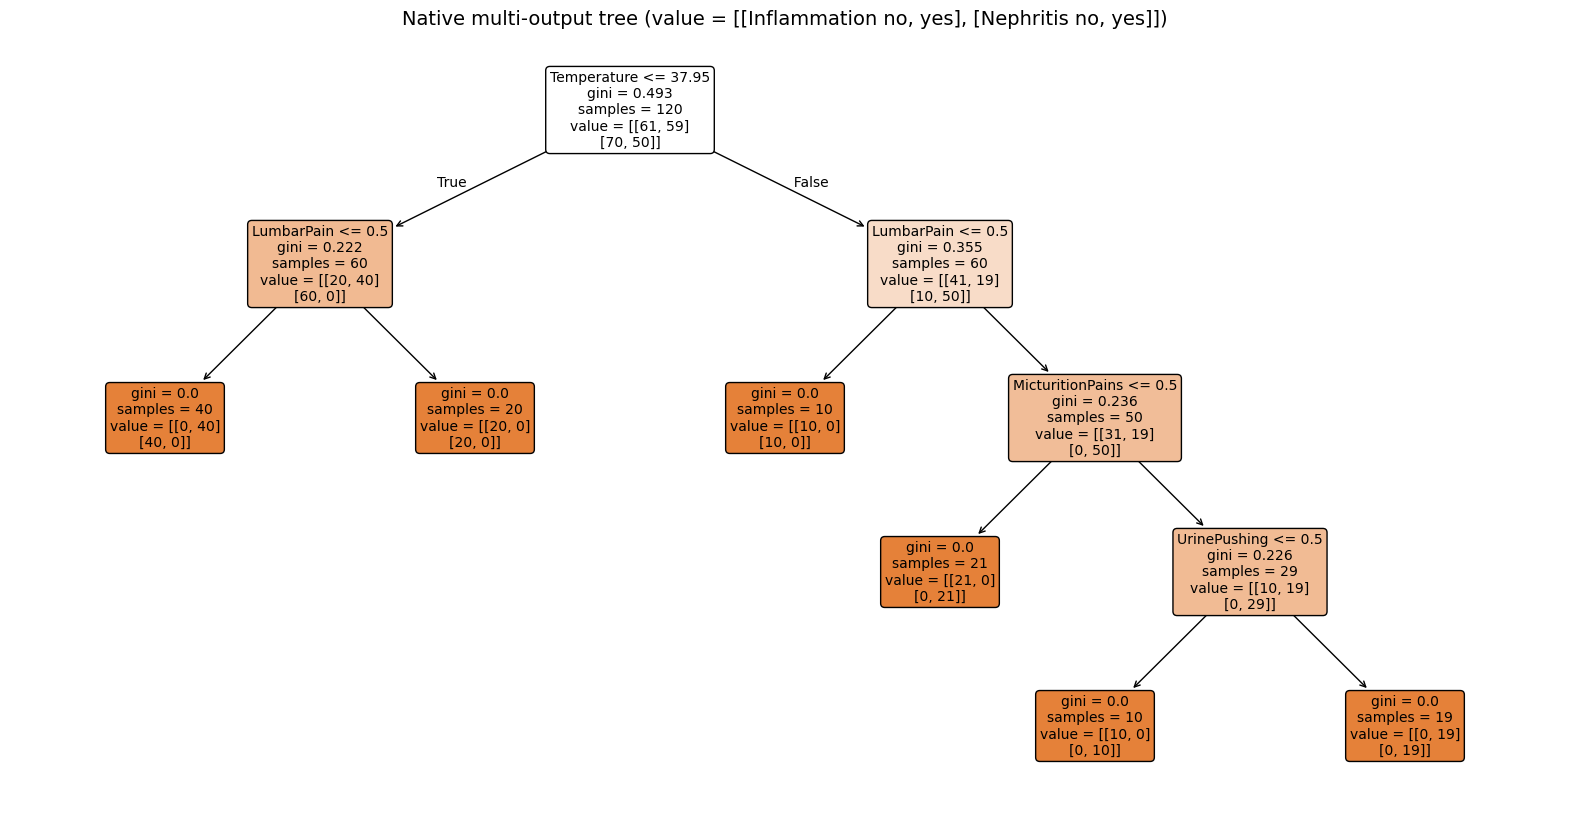

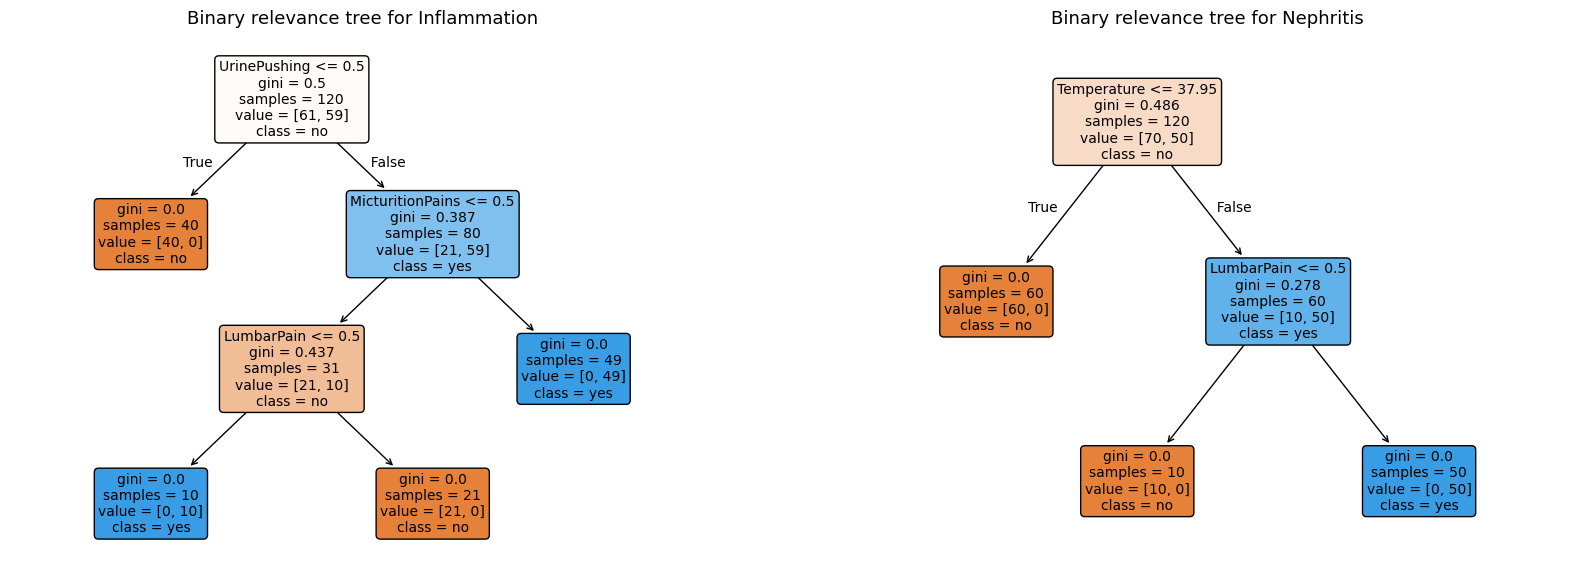

,total leaves,max depth,mean CV errors (of 120),mean CV exact-match accuracy
Label powerset,6,4,1.48,0.9877
Multi-output tree,6,4,0.56,0.9953
Binary relevance,7,3,0.56,0.9953


In [4]:
# Native multi-output tree: predicts both labels at once
tree_mo = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X1, Y1)

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(tree_mo, feature_names=features, filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title('Native multi-output tree (value = [[Inflammation no, yes], [Nephritis no, yes]])', fontsize=14)
plt.show()

# Binary relevance: one tree per label
tree_br = {lab: DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X1, Y1[lab]) for lab in labels}

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, lab in zip(axes, labels):
    plot_tree(tree_br[lab], feature_names=features, class_names=['no', 'yes'],
              filled=True, rounded=True, fontsize=10, ax=ax)
    ax.set_title(f'Binary relevance tree for {lab}', fontsize=13)
plt.show()

# Compare the three approaches with 5-fold CV, repeated with 50 different random splits.
# A patient counts as correct only if BOTH labels are predicted correctly
inv_map = {v: k for k, v in lp_map.items()}

def exact_match_errors(approach, seed):
    #Number of patients (out of 120) with at least one wrong label in one round of 5-fold CV
    errors = 0
    for tr, te in KFold(n_splits=5, shuffle=True, random_state=seed).split(X1):
        Xtr, Xte, Ytr, Yte = X1.iloc[tr], X1.iloc[te], Y1.iloc[tr], Y1.iloc[te]
        if approach == 'Label powerset':
            m = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, y_lp.iloc[tr])
            pred = np.array([inv_map[c] for c in m.predict(Xte)])
        elif approach == 'Multi-output tree':
            pred = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, Ytr).predict(Xte)
        else:  # binary relevance
            pred = np.column_stack([DecisionTreeClassifier(random_state=RANDOM_STATE)
                                    .fit(Xtr, Ytr[lab]).predict(Xte) for lab in labels])
        errors += int((~(pred == Yte.values).all(axis=1)).sum())
    return errors

approaches = ['Label powerset', 'Multi-output tree', 'Binary relevance']
errors = pd.DataFrame({a: [exact_match_errors(a, seed) for seed in range(50)] for a in approaches})

comparison = pd.DataFrame({
    'total leaves': [tree_lp.get_n_leaves(), tree_mo.get_n_leaves(),
                     sum(t.get_n_leaves() for t in tree_br.values())],
    'max depth': [tree_lp.get_depth(), tree_mo.get_depth(),
                  max(t.get_depth() for t in tree_br.values())],
    'mean CV errors (of 120)': errors.mean().values,
    'mean CV exact-match accuracy': (1 - errors.mean() / len(X1)).values,
}, index=approaches)
display(comparison.round(4))

**Is the label powerset approach right here?** It is a reasonable choice, since there are only 4 label combinations and each has 19–40 patients, but it is not best among all choices: from the frame above, it is slightly less accurate (98.8% exact-match accuracy) than the multi-output tree and binary relevance (both 99.5%), and binary relevance also gives simpler trees.

### (c) Convert the decision rules

The function below walks the fitted tree from the root to every leaf (adapted from the KDnuggets code). Each root-to-leaf path becomes one IF-THEN rule. Because the five symptom features are binary (0/1), a split such as `Nausea <= 0.5` is printed as `Nausea = no`.

In [5]:
BINARY = set(features) - {'Temperature'}

def tree_to_rules(clf, feature_names, class_names):
    #Return a list of (conditions, predicted class, n samples, class purity) for every leaf
    t = clf.tree_
    rules = []

    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:          # to identify if the node is a leaf
            name, thr = feature_names[t.feature[node]], t.threshold[node]
            left = f'{name} = no' if name in BINARY else f'{name} <= {thr:.2f}'
            right = f'{name} = yes' if name in BINARY else f'{name} > {thr:.2f}'
            recurse(t.children_left[node], conds + [left])
            recurse(t.children_right[node], conds + [right])
        else:                                                
            dist = t.value[node][0]
            dist = dist / dist.sum()
            rules.append((conds, class_names[int(np.argmax(dist))], int(t.n_node_samples[node]), dist.max()))

    recurse(0, [])
    return rules

def print_rules(clf, feature_names, class_names, title):
    print(title)
    for i, (conds, cls, n, purity) in enumerate(tree_to_rules(clf, feature_names, class_names), 1):
        print(f'  Rule {i}: IF {" AND ".join(conds) if conds else "TRUE"}'
              f'\n          THEN diagnosis = {cls}   [{n} patients, {purity:.0%} pure]')
    print()

print_rules(tree_lp, features, list(tree_lp.classes_), 'IF-THEN rules of the label powerset tree:')

IF-THEN rules of the label powerset tree:
  Rule 1: IF LumbarPain = no AND UrinePushing = no
          THEN diagnosis = none   [10 patients, 100% pure]
  Rule 2: IF LumbarPain = no AND UrinePushing = yes
          THEN diagnosis = inflammation only   [40 patients, 100% pure]
  Rule 3: IF LumbarPain = yes AND Temperature <= 37.95
          THEN diagnosis = none   [20 patients, 100% pure]
  Rule 4: IF LumbarPain = yes AND Temperature > 37.95 AND MicturitionPains = no
          THEN diagnosis = nephritis only   [21 patients, 100% pure]
  Rule 5: IF LumbarPain = yes AND Temperature > 37.95 AND MicturitionPains = yes AND UrinePushing = no
          THEN diagnosis = nephritis only   [10 patients, 100% pure]
  Rule 6: IF LumbarPain = yes AND Temperature > 37.95 AND MicturitionPains = yes AND UrinePushing = yes
          THEN diagnosis = both   [19 patients, 100% pure]



The six rules of the label powerset tree cover all 120 patients, and every leaf is 100% pure. In words:

- **No lumbar pain:** the patient has bladder inflammation only if there is urine pushing; otherwise the patient has neither disease.
- **Lumbar pain, temperature ≤ 37.95 °C:** neither disease.
- **Lumbar pain, temperature > 37.95 °C:** nephritis. If the patient also has both micturition pains and urine pushing, the diagnosis is both diseases.

### (d) Cost-complexity pruning

Cost-complexity pruning minimizes $R_\alpha(T) = R(T) + \alpha |T|$, where $R(T)$ is the total (sample-weighted) leaf impurity and $|T|$ is the number of leaves. As $\alpha$ grows, the tree is pruned back through a nested sequence of subtrees. I compute this sequence with `cost_complexity_pruning_path`, estimate the accuracy of each subtree with stratified 5-fold cross-validation, and choose the **largest** $\alpha$ (which makes the smallest tree) whose CV accuracy is within one standard error of the best one.

,alpha,leaves,depth,total leaf impurity,train acc,CV acc,CV se
0,0.0000,6,4,0.0000,1.0000,0.9917,0.0083
1,0.0982,4,2,0.1963,0.8417,0.8583,0.0250
2,0.1333,3,2,0.3297,0.7583,0.7667,0.0312
3,0.1820,2,1,0.5117,0.5917,0.6750,0.0333
4,0.2229,1,0,0.7346,0.3333,0.4833,0.0612


Best CV accuracy = 0.992; one-SE threshold = 0.983
Chosen alpha = 0.0000


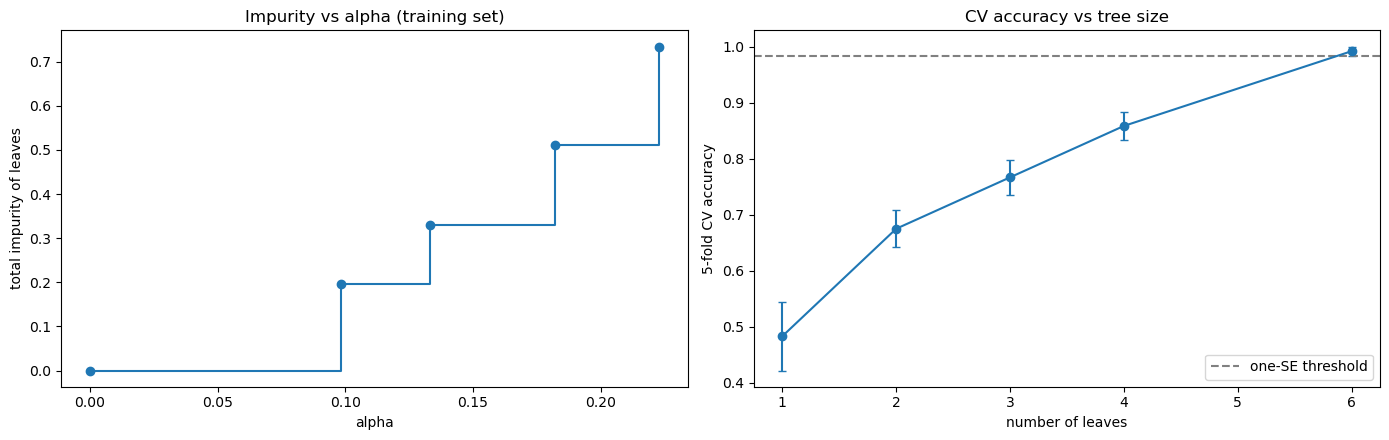

In [6]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X1, y_lp)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows = []
for a, imp in zip(path.ccp_alphas, path.impurities):
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    scores = cross_val_score(clf, X1, y_lp, cv=skf, scoring='accuracy')
    clf.fit(X1, y_lp)
    rows.append({'alpha': a, 'leaves': clf.get_n_leaves(), 'depth': clf.get_depth(),
                 'total leaf impurity': imp, 'train acc': clf.score(X1, y_lp),
                 'CV acc': scores.mean(), 'CV se': scores.std(ddof=1) / np.sqrt(len(scores))})
prune = pd.DataFrame(rows)
display(prune.round(4))

best = prune['CV acc'].idxmax()
threshold = prune.loc[best, 'CV acc'] - prune.loc[best, 'CV se']
chosen = prune[prune['CV acc'] >= threshold]['alpha'].max()
print(f'Best CV accuracy = {prune.loc[best, "CV acc"]:.3f}; one-SE threshold = {threshold:.3f}')
print(f'Chosen alpha = {chosen:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(prune['alpha'], prune['total leaf impurity'], 'o-', drawstyle='steps-post')
axes[0].set(xlabel='alpha', ylabel='total impurity of leaves', title='Impurity vs alpha (training set)')
axes[1].errorbar(prune['leaves'], prune['CV acc'], yerr=prune['CV se'], fmt='o-', capsize=3)
axes[1].axhline(threshold, ls='--', c='gray', label='one-SE threshold')
axes[1].set(xlabel='number of leaves', ylabel='5-fold CV accuracy', title='CV accuracy vs tree size')
axes[1].legend()
plt.tight_layout()
plt.show()

Pruned tree: leaves = 6, depth = 4, training accuracy = 1.000


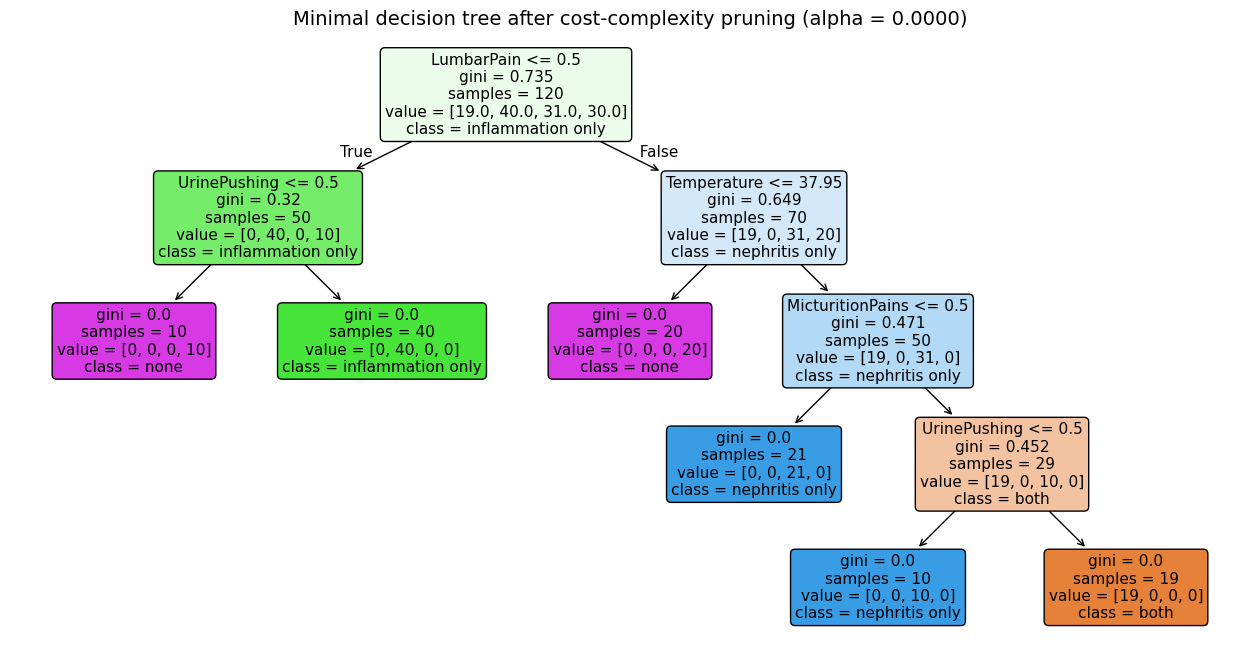

IF-THEN rules of the pruned tree:
  Rule 1: IF LumbarPain = no AND UrinePushing = no
          THEN diagnosis = none   [10 patients, 100% pure]
  Rule 2: IF LumbarPain = no AND UrinePushing = yes
          THEN diagnosis = inflammation only   [40 patients, 100% pure]
  Rule 3: IF LumbarPain = yes AND Temperature <= 37.95
          THEN diagnosis = none   [20 patients, 100% pure]
  Rule 4: IF LumbarPain = yes AND Temperature > 37.95 AND MicturitionPains = no
          THEN diagnosis = nephritis only   [21 patients, 100% pure]
  Rule 5: IF LumbarPain = yes AND Temperature > 37.95 AND MicturitionPains = yes AND UrinePushing = no
          THEN diagnosis = nephritis only   [10 patients, 100% pure]
  Rule 6: IF LumbarPain = yes AND Temperature > 37.95 AND MicturitionPains = yes AND UrinePushing = yes
          THEN diagnosis = both   [19 patients, 100% pure]



In [7]:
#build a new tree with the chosen alpha 0

tree_pruned = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=chosen).fit(X1, y_lp)
print(f'Pruned tree: leaves = {tree_pruned.get_n_leaves()}, depth = {tree_pruned.get_depth()}, '
      f'training accuracy = {tree_pruned.score(X1, y_lp):.3f}')

fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(tree_pruned, feature_names=features, class_names=list(tree_pruned.classes_),
          filled=True, rounded=True, fontsize=11, ax=ax)
ax.set_title(f'Minimal decision tree after cost-complexity pruning (alpha = {chosen:.4f})', fontsize=14)
plt.show()

print_rules(tree_pruned, features, list(tree_pruned.classes_), 'IF-THEN rules of the pruned tree:')

**Result.** After cross-validation with the one-SE rule,we choose $\alpha = 0$: pruning even one branch drops CV accuracy from 99.2% to 85.8%, below the one-SE threshold of 98.3%. The selected tree is therefore the full 6-leaf tree, and its six IF-THEN rules above are the final rule set.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

The column names are read from the `@attribute` lines of `communities.names`. Missing values are coded as `?`. The first 1495 rows are the training set and the remaining 499 rows are the test set.

In [8]:
attr_names = [re.match(r'@attribute\s+(\S+)', line).group(1)
              for line in open(DATA_DIR / 'communities.names', encoding='latin-1')
              if line.startswith('@attribute')]
crime = pd.read_csv(DATA_DIR / 'communities.data', header=None, names=attr_names, na_values='?')
print('Shape:', crime.shape)
display(crime.head())

N_TRAIN = 1495
print(f'Training rows: {N_TRAIN}, test rows: {len(crime) - N_TRAIN}')

Shape: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Training rows: 1495, test rows: 499


### (b) Missing values

According to the data description, `state`, `county`, `community`, `communityname` and `fold` are non-predictive, so we ignore them. This leaves 122 predictive features and the target `ViolentCrimesPerPop`.

Missing values are imputed with the **median** of each feature. The medians are computed on the **training set only**, so no information from the test set leaks into training. The reason I choose median instead of mean is because many features are skewed (lots of values bunched near 0 or capped at 1), so median might minimize the influence.

In [9]:
nonpredictive = ['state', 'county', 'community', 'communityname', 'fold']
target = 'ViolentCrimesPerPop'
data = crime.drop(columns=nonpredictive)

X = data.drop(columns=target)
y = data[target]
X_train_raw, X_test_raw = X.iloc[:N_TRAIN], X.iloc[N_TRAIN:]
y_train, y_test = y.iloc[:N_TRAIN], y.iloc[N_TRAIN:]
print('Number of predictive features:', X.shape[1])

miss = X.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print(f'\n{len(miss)} features have missing values:')
display(pd.DataFrame({'missing (all rows)': miss,
                      'missing (train)': X_train_raw[miss.index].isna().sum(),
                      'missing (test)': X_test_raw[miss.index].isna().sum(),
                      '% missing': (100 * miss / len(X)).round(1)}))

imputer = SimpleImputer(strategy='median').fit(X_train_raw)
X_train = pd.DataFrame(imputer.transform(X_train_raw), columns=X.columns, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X.columns, index=X_test_raw.index)
X_all = pd.concat([X_train, X_test])
print('Missing values left after imputation:', int(X_all.isna().sum().sum()))

Number of predictive features: 122

23 features have missing values:


,missing (all rows),missing (train),missing (test),% missing
PctPolicBlack,1675,1256,419,84.0
PctPolicHisp,1675,1256,419,84.0
LemasGangUnitDeploy,1675,1256,419,84.0
LemasPctPolicOnPatr,1675,1256,419,84.0
PolicOperBudg,1675,1256,419,84.0
PolicCars,1675,1256,419,84.0
PolicAveOTWorked,1675,1256,419,84.0
NumKindsDrugsSeiz,1675,1256,419,84.0
OfficAssgnDrugUnits,1675,1256,419,84.0
PctPolicMinor,1675,1256,419,84.0


Missing values left after imputation: 0


**Comment.** 23 features have missing values. `OtherPerCap` is missing in one row only. The other 22 are police features from the LEMAS survey, missing for 84% of the communities. The imputation is a strong assumption because the values are not missing at random. So maybe reasonable alternatives would be to drop these features or to add a "missing" indicator.

### (c) Plot a correlation matrix

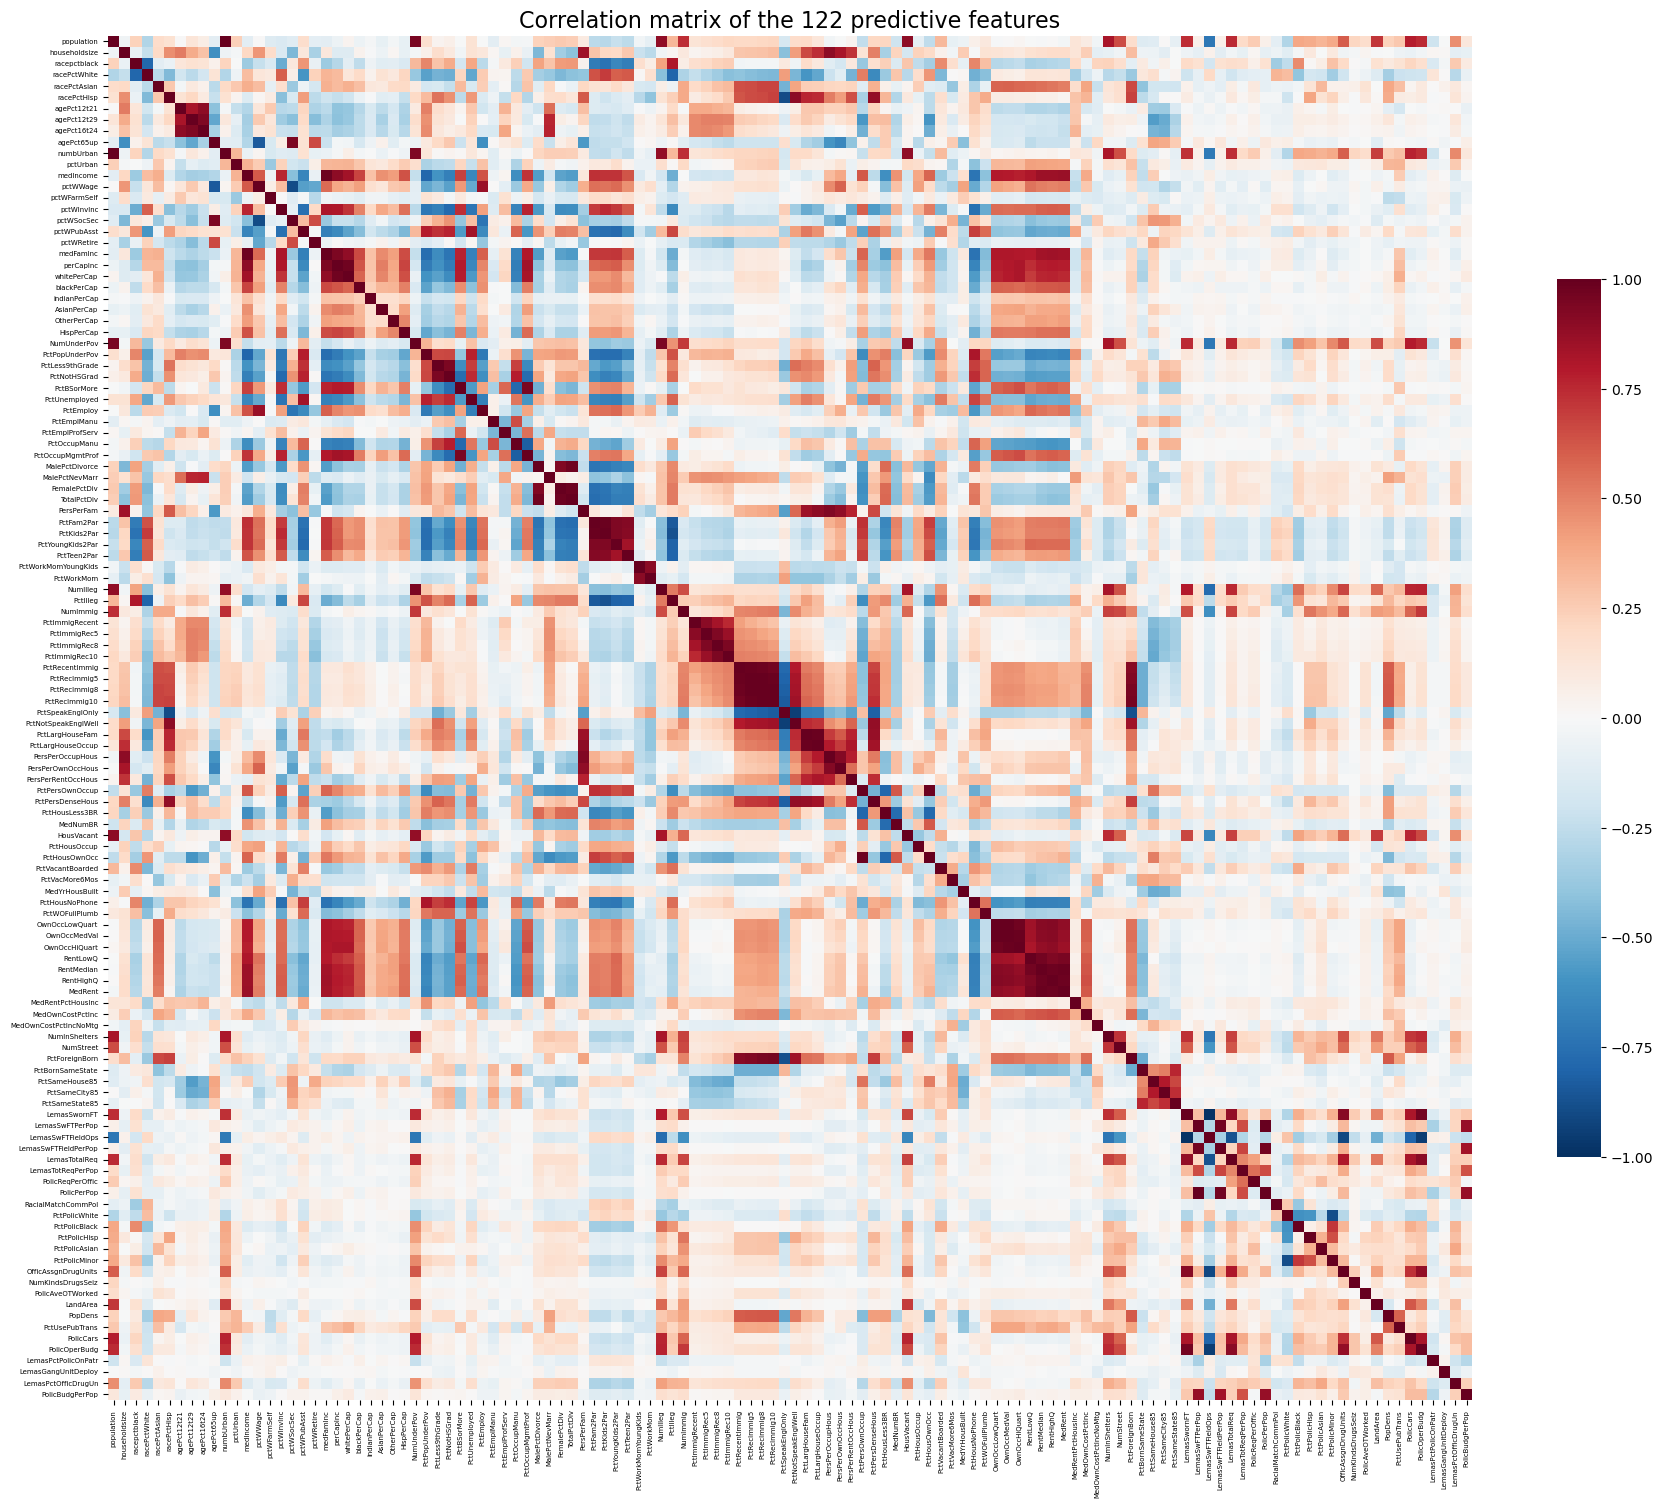

10 most strongly correlated feature pairs:
LemasSwFTPerPop  PolicPerPop          1.000
PctRecImmig8     PctRecImmig10        0.996
OwnOccLowQuart   OwnOccMedVal         0.994
PctRecImmig5     PctRecImmig8         0.993
population       numbUrban            0.993
LemasSwornFT     LemasSwFTFieldOps   -0.992
OwnOccMedVal     OwnOccHiQuart        0.991
PctRecentImmig   PctRecImmig5         0.989
RentMedian       MedRent              0.989
PctRecImmig5     PctRecImmig10        0.986

Features most correlated with ViolentCrimesPerPop:
PctKids2Par        -0.738
PctIlleg            0.738
PctFam2Par         -0.707
racePctWhite       -0.685
PctYoungKids2Par   -0.666
PctTeen2Par        -0.662
racepctblack        0.631
pctWInvInc         -0.576
pctWPubAsst         0.575
FemalePctDiv        0.556


In [10]:
corr = X_all.corr()

fig, ax = plt.subplots(figsize=(22, 19))
sns.heatmap(corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={'shrink': 0.6}, ax=ax)
ax.tick_params(labelsize=5)
ax.set_title('Correlation matrix of the 122 predictive features', fontsize=16)
plt.show()

# Strongest pairwise correlations (upper triangle only, so each pair appears once)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top_pairs = upper.reindex(upper.abs().sort_values(ascending=False).index).head(10)
print('10 most strongly correlated feature pairs:')
print(top_pairs.round(3).to_string())

# Correlation of each feature with the target
corr_y = X_all.corrwith(pd.concat([y_train, y_test]))
print('\nFeatures most correlated with ViolentCrimesPerPop:')
print(corr_y.reindex(corr_y.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

**Comment.** The matrix shows large blocks of strongly correlated features, and some pairs measure essentially the same thing (e.g. `LemasSwFTPerPop` and `PolicPerPop`, r = 1.000; `PctRecImmig8` and `PctRecImmig10`, r = 0.996; `population` and `numbUrban`, r = 0.993). Income/poverty and family-structure variables also form strongly correlated blocks. This multicollinearity makes least squares coefficients unstable， so this motivates the regularized and dimension-reduction methods below. ViolentCrimesPerPop is most strongly correlated with family-structure variables (`PctKids2Par`, r = −0.74; `PctIlleg`, r = 0.74).

### (d) Calculate the Coefficient of Variation CV

In [11]:
cv_table = pd.DataFrame({'mean': X_all.mean(), 'std': X_all.std(ddof=1)})
cv_table['CV'] = cv_table['std'] / cv_table['mean']
cv_table = cv_table.sort_values('CV', ascending=False)
display(cv_table.round(4))

,mean,std,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017


### (e) Scatter plots and box plots for highest CV features

In [12]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv_table.index[:k].tolist()
print(f'floor(sqrt(128)) = {k} features with the highest CV:')
print(cv_table.loc[top_cv, 'CV'].round(3).to_string())

floor(sqrt(128)) = 11 features with the highest CV:
PctPolicAsian          5.448
NumStreet              4.408
NumInShelters          3.485
NumIlleg               2.994
NumImmig               2.900
LemasPctOfficDrugUn    2.555
NumUnderPov            2.305
population             2.204
LemasSwornFT           2.081
numbUrban              2.002
HousVacant             1.959


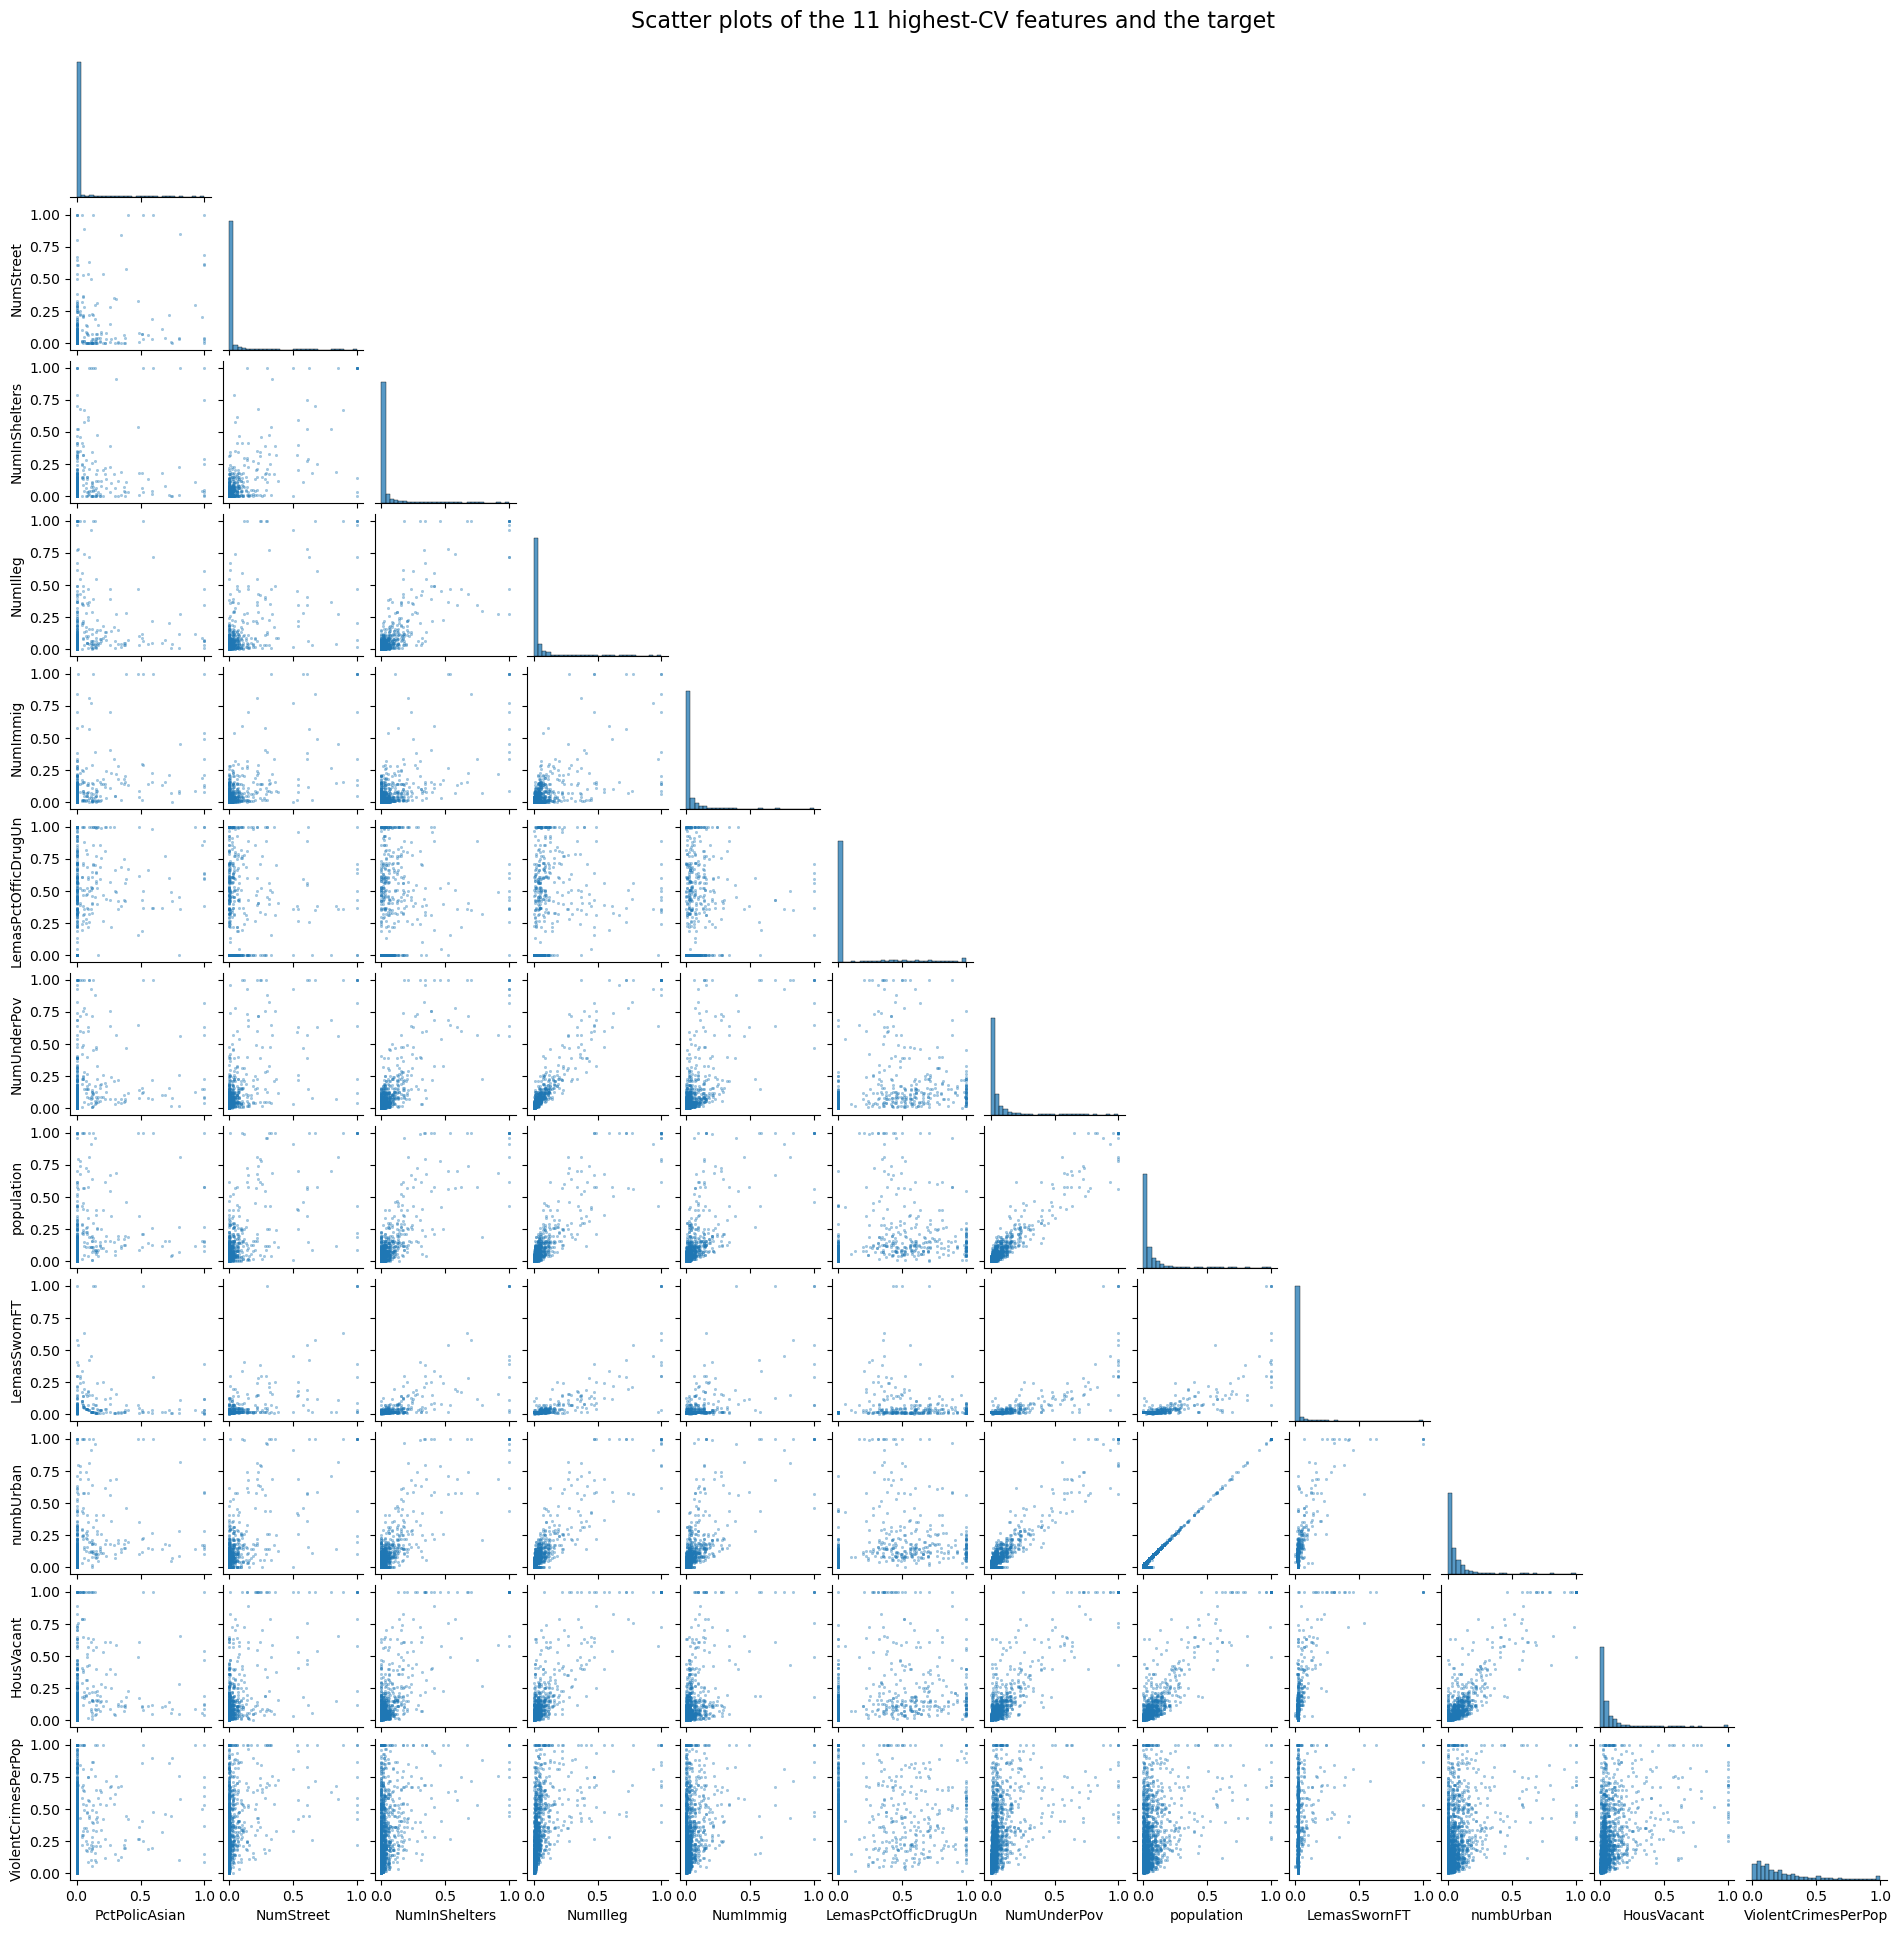

In [13]:
# Scatter-plot matrix of the 11 features together with the target(ViolentCrimesPerPop)
plot_df = X_all[top_cv].assign(ViolentCrimesPerPop=pd.concat([y_train, y_test]))
g = sns.pairplot(plot_df, corner=True, height=1.6, plot_kws={'s': 4, 'alpha': 0.4, 'edgecolor': None},
                 diag_kws={'bins': 30})
g.fig.suptitle('Scatter plots of the 11 highest-CV features and the target', y=1.01, fontsize=16)
plt.show()

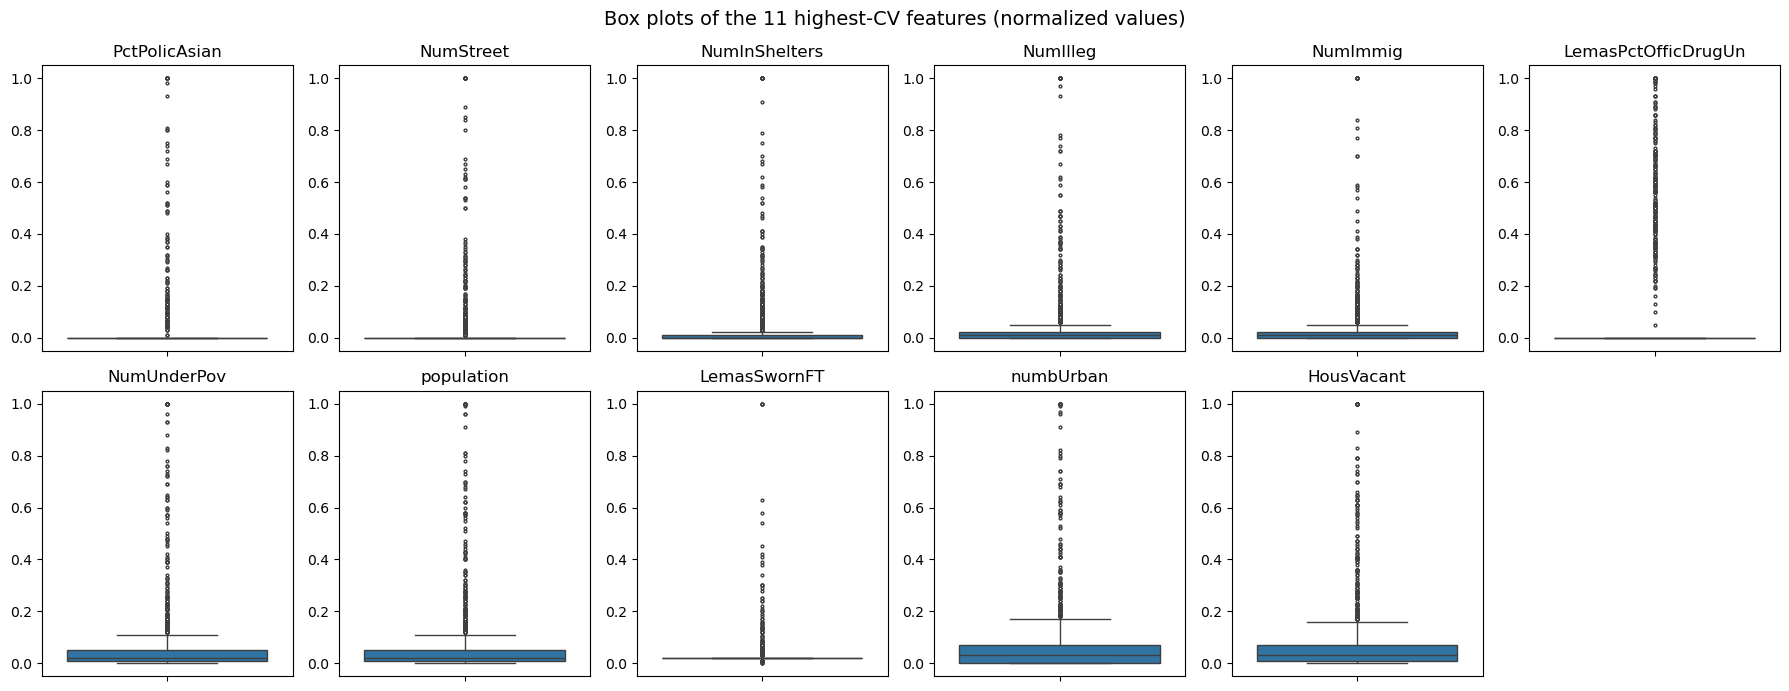

In [14]:
# Box plots: one panel per feature (own y-axis, so each box is readable)
fig, axes = plt.subplots(2, 6, figsize=(18, 7))
for ax, f in zip(axes.ravel(), top_cv):
    sns.boxplot(y=X_all[f], ax=ax, fliersize=2, color='tab:blue')
    ax.set(title=f, ylabel='')
axes.ravel()[-1].axis('off')
fig.suptitle('Box plots of the 11 highest-CV features (normalized values)', fontsize=14)
plt.tight_layout()
plt.show()

**We can't draw conclusions about the significance of these features just from the scatter plots**
<br>Scatter plots show only marginal relationships,visually: they give no test statistic or p-value, and significance in a regression refers to a feature's effect when all the other features are held. Here the picture is even more complex, because the features are heavily right-skewed (box plots: most values near 0, a few large cities at the cap of 1), and several are counts that rise almost linearly with population (`NumIlleg`, `HousVacant`, `NumUnderPov` and `numbUrban`), so their association with the target may simply reflect city size. A formal test (such as the t-tests of the coefficients in a multiple regression), would be needed.

### (f) Fit a linear model

In [15]:
test_mse = {}   # collect test errors of all models

ols = LinearRegression().fit(X_train, y_train)
test_mse['Linear regression (OLS)'] = mean_squared_error(y_test, ols.predict(X_test))
print(f'Training MSE: {mean_squared_error(y_train, ols.predict(X_train)):.5f}')
print(f'Test MSE:     {test_mse["Linear regression (OLS)"]:.5f}')
print(f'Test R^2:     {r2_score(y_test, ols.predict(X_test)):.4f}')
print(f'Largest |coefficient|: {np.abs(ols.coef_).max():.2f}')

Training MSE: 0.01629
Test MSE:     0.01797
Test R^2:     0.6222
Largest |coefficient|: 0.89


**Comment.** The least squares model has a **test MSE of 0.0180** (test $R^2$ ≈ 0.62). The training MSE (0.0163) is only modestly lower, so overfitting is mild. However, some features are almost perfectly correlated (eg. `LemasSwFTPerPop` and `PolicPerPop`, r = 1.000 in part (c)), so the OLS coefficients are not uniquely determined and individual coefficients cannot be interpreted. This multicollinearity motivates the regularized and dimension-reduction methods below.

### (g) Fit a ridge regression model

$\lambda$ (`alpha` in scikit-learn) is chosen by 10-fold cross-validation over a log-spaced grid, using MSE as the criterion. The same folds are used for every model in parts (g)–(j).

Lambda chosen by 10-fold CV: 2.1544
CV MSE at that lambda:       0.01904
Test MSE:                    0.01753


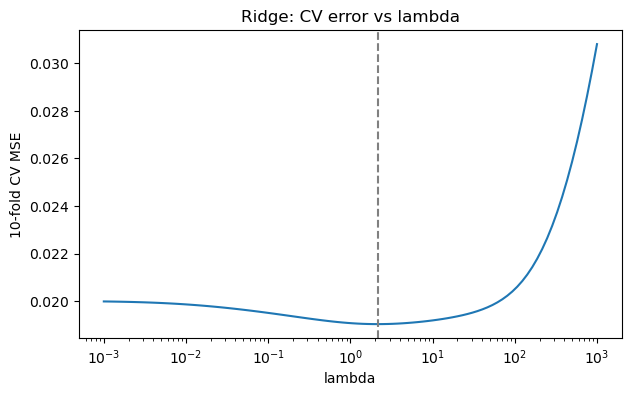

In [16]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

ridge_grid = GridSearchCV(Ridge(), {'alpha': np.logspace(-3, 3, 100)}, cv=kf,
                          scoring='neg_mean_squared_error').fit(X_train, y_train)
ridge = ridge_grid.best_estimator_
test_mse['Ridge'] = mean_squared_error(y_test, ridge.predict(X_test))
print(f'Lambda chosen by 10-fold CV: {ridge_grid.best_params_["alpha"]:.4f}')
print(f'CV MSE at that lambda:       {-ridge_grid.best_score_:.5f}')
print(f'Test MSE:                    {test_mse["Ridge"]:.5f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(ridge_grid.cv_results_['param_alpha'].astype(float), -ridge_grid.cv_results_['mean_test_score'])
ax.axvline(ridge_grid.best_params_['alpha'], ls='--', c='gray')
ax.set(xlabel='lambda', ylabel='10-fold CV MSE', title='Ridge: CV error vs lambda')
plt.show()

**Comment.** 10-fold CV chooses $\lambda \approx 2.15$. The ridge test MSE (0.0175) is slightly lower than OLS (0.0180). Ridge shrinks the coefficients, trading a little bias for lower variance; but with a single test set of 499 communities, the small difference in test MSE is not clear evidence that ridge predicts better.

### (h) Fit a LASSO model

In [17]:
# Case 1: normalized features as given
lasso = LassoCV(cv=kf, n_jobs=-1, max_iter=100000, random_state=RANDOM_STATE).fit(X_train, y_train)
test_mse['LASSO (normalized features)'] = mean_squared_error(y_test, lasso.predict(X_test))
sel_raw = X.columns[lasso.coef_ != 0]
print(f'Lambda chosen by 10-fold CV: {lasso.alpha_:.6f}')
print(f'Test MSE: {test_mse["LASSO (normalized features)"]:.5f}')
print(f'{len(sel_raw)} of {X.shape[1]} variables selected:')
display(pd.Series(lasso.coef_[lasso.coef_ != 0], index=sel_raw, name='coefficient')
        .sort_values(key=np.abs, ascending=False).round(4).to_frame())

Lambda chosen by 10-fold CV: 0.000082
Test MSE: 0.01769
79 of 122 variables selected:


,coefficient
agePct12t29,-0.3203
racepctblack,0.2698
PctPersDenseHous,0.2382
PctKids2Par,-0.2014
MedRent,0.1830
PctEmploy,0.1755
MalePctNevMarr,0.1723
RentLowQ,-0.1714
NumStreet,0.1638
PctPopUnderPov,-0.1601


In [18]:
# Case 2: standardized features
lasso_std = Pipeline([('scale', StandardScaler()),
                      ('lasso', LassoCV(cv=kf, n_jobs=-1, max_iter=100000, random_state=RANDOM_STATE))])
lasso_std.fit(X_train, y_train)
coef_std = lasso_std.named_steps['lasso'].coef_
test_mse['LASSO (standardized features)'] = mean_squared_error(y_test, lasso_std.predict(X_test))
sel_std = X.columns[coef_std != 0]
print(f'Lambda chosen by 10-fold CV: {lasso_std.named_steps["lasso"].alpha_:.6f}')
print(f'Test MSE: {test_mse["LASSO (standardized features)"]:.5f}')
print(f'{len(sel_std)} of {X.shape[1]} variables selected:')
display(pd.Series(coef_std[coef_std != 0], index=sel_std, name='coefficient (per 1 SD)')
        .sort_values(key=np.abs, ascending=False).round(4).to_frame())

Lambda chosen by 10-fold CV: 0.000619
Test MSE: 0.01773
76 of 122 variables selected:


,coefficient (per 1 SD)
racepctblack,0.0681
agePct12t29,-0.0438
PctPersDenseHous,0.0437
PctKids2Par,-0.0406
RentLowQ,-0.0311
MedRent,0.0309
PctPopUnderPov,-0.0297
PctEmploy,0.0255
MalePctNevMarr,0.0251
PctIlleg,0.0238


Selected in both cases: 75
Only with normalized features:   ['PctBSorMore', 'PctWorkMomYoungKids', 'agePct65up', 'medFamInc']
Only with standardized features: ['PctImmigRecent']


,test MSE,variables selected
"normalized [0,1]",0.01769,79
standardized,0.01773,76


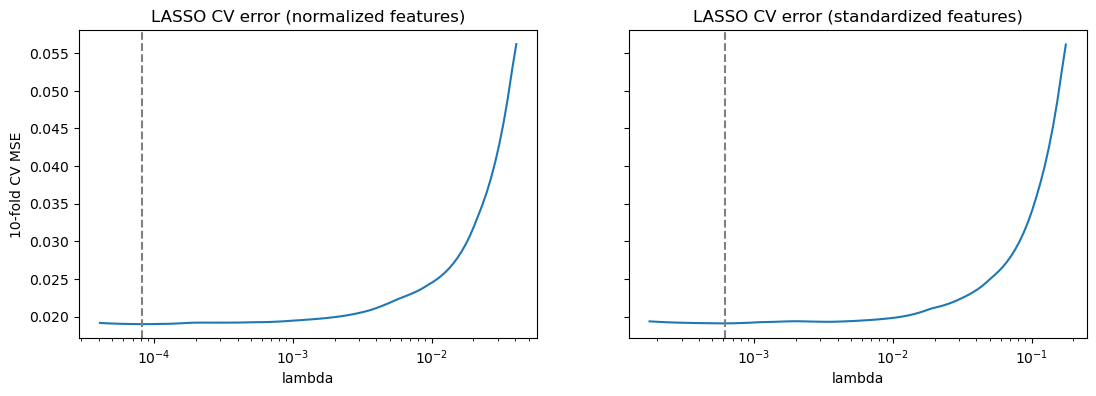

In [19]:
# Comparison of the two LASSO fits
both = sorted(set(sel_raw) & set(sel_std))
print(f'Selected in both cases: {len(both)}')
print(f'Only with normalized features:   {sorted(set(sel_raw) - set(sel_std))}')
print(f'Only with standardized features: {sorted(set(sel_std) - set(sel_raw))}')
display(pd.DataFrame({'test MSE': [test_mse['LASSO (normalized features)'], test_mse['LASSO (standardized features)']],
                      'variables selected': [len(sel_raw), len(sel_std)]},
                     index=['normalized [0,1]', 'standardized']).round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, m, name in [(axes[0], lasso, 'normalized features'),
                    (axes[1], lasso_std.named_steps['lasso'], 'standardized features')]:
    ax.semilogx(m.alphas_, m.mse_path_.mean(axis=1))
    ax.axvline(m.alpha_, ls='--', c='gray')
    ax.set(xlabel='lambda', title=f'LASSO CV error ({name})')
axes[0].set_ylabel('10-fold CV MSE')
plt.show()

**Comparison.**

| | normalized [0,1] features | standardized features |
|---|---|---|
| λ chosen by CV | ≈ 8.2e-5 | ≈ 6.2e-4 |
| variables selected | 79 / 122 | 76 / 122 |
| test MSE | 0.01769 | 0.01773 |

- **The two fits are almost identical.** The test MSEs differ by only 0.00004, and 75 variables are selected in both cases. Both test MSEs are within a small margin of OLS and ridge.
- **Why standardization matters in general:** the L1 penalty acts on the size of the coefficients, and the size of a coefficient depends on the scale of its feature, so without standardization features measured on a small scale are penalized more heavily. Here the features were already min–max normalized to [0, 1], so standardizing changes the result only a little. The two λ values are not directly comparable because the features are on different scales.
PS.When features are highly correlated, the LASSO tends to keep one variable from each group and drop the rest, so the selected list is one good predictive subset, not the only set of relevant variables.

### (i) Fit a PCR model

M chosen by 10-fold CV: 97 (explains 99.9% of the feature variance)
CV MSE at M = 97: 0.01949
Test MSE: 0.01837


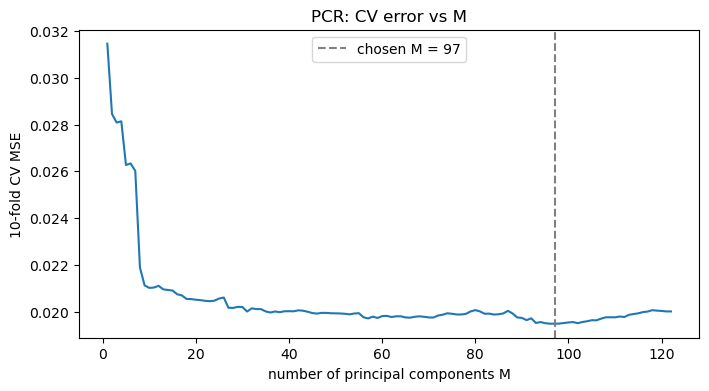

In [20]:
pcr = Pipeline([('scale', StandardScaler()), ('pca', PCA()), ('ols', LinearRegression())])
pcr_grid = GridSearchCV(pcr, {'pca__n_components': list(range(1, X.shape[1] + 1))}, cv=kf,
                        scoring='neg_mean_squared_error', n_jobs=-1).fit(X_train, y_train)
M = pcr_grid.best_params_['pca__n_components']
test_mse['PCR'] = mean_squared_error(y_test, pcr_grid.predict(X_test))

cv_mse = -pcr_grid.cv_results_['mean_test_score']
evr = pcr_grid.best_estimator_.named_steps['pca'].explained_variance_ratio_.sum()

print(f'M chosen by 10-fold CV: {M} (explains {evr:.1%} of the feature variance)')
print(f'CV MSE at M = {M}: {cv_mse[M - 1]:.5f}')
print(f'Test MSE: {test_mse["PCR"]:.5f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(cv_mse) + 1), cv_mse)
ax.axvline(M, ls='--', c='gray', label=f'chosen M = {M}')
ax.set(xlabel='number of principal components M', ylabel='10-fold CV MSE', title='PCR: CV error vs M')
ax.legend()
plt.show()

**Comment.** 10-fold CV chooses M = 97 components (99.9% of the feature variance), with a **test MSE of 0.0184**, the highest of the linear methods; with M close to p = 122, PCR is nearly the same as OLS. The CV error drops sharply over the first ~10 components and is almost flat after about 20, so many values of M give similar CV error and the exact minimum at 97 is partly due to noise. A likely reason why so many components are needed is that PCA chooses directions by the variance of the features, without looking at the response.

### (j) Fit a boosting tree

**Method.** The L1 penalty on each node corresponds to XGBoost's `reg_alpha` ($\alpha$), an L1 penalty on the leaf values that shrinks them towards 0 as in the LASSO. I set the L2 penalty `reg_lambda` to 0 so the penalty is purely L1, keep the other hyperparameters at XGBoost's defaults, and choose $\alpha$ by 10-fold CV.

,alpha,CV MSE
0,0.00,0.02319
1,0.01,0.02261
2,0.03,0.02293
3,0.10,0.02205
4,0.30,0.02216
5,1.00,0.02064
6,3.00,0.02051
7,10.00,0.02168
8,30.00,0.02652


alpha chosen by 10-fold CV: 3
Test MSE: 0.01698


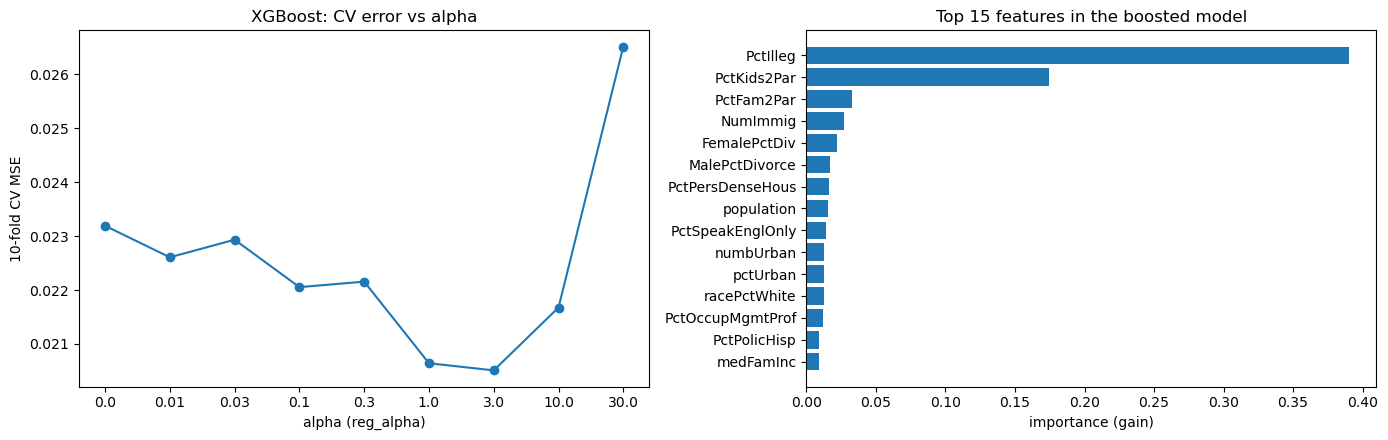

In [21]:
xgb = XGBRegressor(objective='reg:squarederror', reg_lambda=0,   # reg_lambda=0: L1 penalty only
                   random_state=RANDOM_STATE, n_jobs=-1)
xgb_grid = GridSearchCV(xgb, {'reg_alpha': [0, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]}, cv=kf,
                        scoring='neg_mean_squared_error').fit(X_train, y_train)
xgb_best = xgb_grid.best_estimator_
test_mse['L1-penalized gradient boosting (XGBoost)'] = mean_squared_error(y_test, xgb_best.predict(X_test))

xgb_cv = pd.DataFrame({'alpha': xgb_grid.cv_results_['param_reg_alpha'].astype(float),
                       'CV MSE': -xgb_grid.cv_results_['mean_test_score']})
display(xgb_cv.round(5))
print(f'alpha chosen by 10-fold CV: {xgb_grid.best_params_["reg_alpha"]}')
print(f'Test MSE: {test_mse["L1-penalized gradient boosting (XGBoost)"]:.5f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(len(xgb_cv)), xgb_cv['CV MSE'], 'o-')
axes[0].set_xticks(range(len(xgb_cv)), xgb_cv['alpha'])
axes[0].set(xlabel='alpha (reg_alpha)', ylabel='10-fold CV MSE', title='XGBoost: CV error vs alpha')
imp = pd.Series(xgb_best.feature_importances_, index=X.columns).nlargest(15)[::-1]
axes[1].barh(imp.index, imp.values)
axes[1].set(xlabel='importance (gain)', title='Top 15 features in the boosted model')
plt.tight_layout()
plt.show()

**Comment.** 10-fold CV chooses $\alpha = 3$, giving a **test MSE of 0.0170**, the lowest of all models (the other hyperparameters were left at XGBoost's defaults, not tuned). Here the L1 penalty clearly helps: the CV error falls from 0.0232 with no penalty to 0.0205 at $\alpha = 3$, maybe because the default trees are deep and fit noise, and the penalty shrinks or removes small leaf values; for $\alpha = 10$ and $30$ the error rises again as the model underfits. The most important features are family-structure variables (`PctIlleg`, `PctKids2Par`, `PctFam2Par`), in line with part (c).

### Summary of test errors

In [22]:
summary = pd.Series(test_mse, name='test MSE').sort_values().to_frame()
summary['test RMSE'] = np.sqrt(summary['test MSE'])
display(summary.round(5))

,test MSE,test RMSE
L1-penalized gradient boosting (XGBoost),0.01698,0.13029
Ridge,0.01753,0.13238
LASSO (normalized features),0.01769,0.13299
LASSO (standardized features),0.01773,0.13314
Linear regression (OLS),0.01797,0.13404
PCR,0.01837,0.13552


**Overall.** The L1-penalized boosting model has the lowest test MSE (0.0170), followed by ridge (0.0175), the two LASSO fits (0.0177), OLS (0.0180) and PCR (0.0184). The differences are small relative to the variability of a single test set of 499 communities, so this ranking is not definitive, and the boosting's slightly better accuracy comes at the cost of interpretability.